In [4]:
Data = "../Data/student-mental-health-6af0c78177816708558847.csv"
print(Data)

../Data/student-mental-health-6af0c78177816708558847.csv


In [79]:
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
import pandas as pd
df = pd.read_csv(Data)
df.head(5)

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [17]:
df.shape

(2000, 17)

In [19]:
df.dtypes

Student_ID                            str
Age                                 int64
Gender                                str
Year_of_Study                       int64
Sleep_Hours                       float64
Study_Hours_Per_Week              float64
GPA                               float64
Social_Media_Hours                float64
Screen_Time_Hours                 float64
Physical_Activity                     str
Financial_Stress                  float64
Family_Support                    float64
Attendance_Rate                   float64
Part_Time_Job                         str
Diet_Quality                          str
Previous_Mental_Health_History        str
Mental_Health_Risk                    str
dtype: object

In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

In [21]:
df.isnull().sum()

Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64

In [23]:
print("nombre de lignes doublons :",df.duplicated().sum())

nombre de lignes doublons : 0


In [46]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,2000.0,21.131500,2.139275,17.0,20.000,21.00,23.00,29.00
Year_of_Study,2000.0,2.630000,1.316802,1.0,1.000,2.00,4.00,5.00
Sleep_Hours,1938.0,6.758875,1.127072,3.3,6.000,6.70,7.60,10.00
Study_Hours_Per_Week,2000.0,19.997900,5.719274,2.4,16.000,19.80,24.00,38.30
GPA,1962.0,2.562503,0.343993,1.5,2.320,2.56,2.79,3.66
Social_Media_Hours,1942.0,6.013955,1.153422,2.1,5.225,6.00,6.70,10.00
Screen_Time_Hours,2000.0,8.548500,1.657571,3.3,7.400,8.50,9.70,14.00
Financial_Stress,1909.0,5.956260,1.893941,1.4,4.500,6.10,7.40,10.00
Family_Support,1946.0,6.518345,1.844639,1.7,5.100,6.70,8.00,9.90
Attendance_Rate,1953.0,85.080236,7.224118,54.4,80.300,85.10,90.00,100.00


In [47]:
df.describe(include=["str"])

,Student_ID,Gender,Physical_Activity,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
count,2000,2000,2000,2000,1931,2000,2000
unique,2000,3,3,2,3,2,3
top,STU0001,Female,Moderate,No,Average,No,High
freq,1,971,906,1289,860,1408,680


In [6]:
df_numeriques = df.select_dtypes(include=["number"])

for col in df_numeriques:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    borne_inferieure = Q1 - IQR * 1.5
    borne_superieure = Q3 + IQR * 1.5

    outliers = df[
        (df[col] > borne_superieure) |
        (df[col] < borne_inferieure)
    ]

    print(f"Les outliers de {col} :", len(outliers))

Les outliers de Age : 4
Les outliers de Year_of_Study : 0
Les outliers de Sleep_Hours : 2
Les outliers de Study_Hours_Per_Week : 7
Les outliers de GPA : 9
Les outliers de Social_Media_Hours : 20
Les outliers de Screen_Time_Hours : 7
Les outliers de Financial_Stress : 0
Les outliers de Family_Support : 0
Les outliers de Attendance_Rate : 12


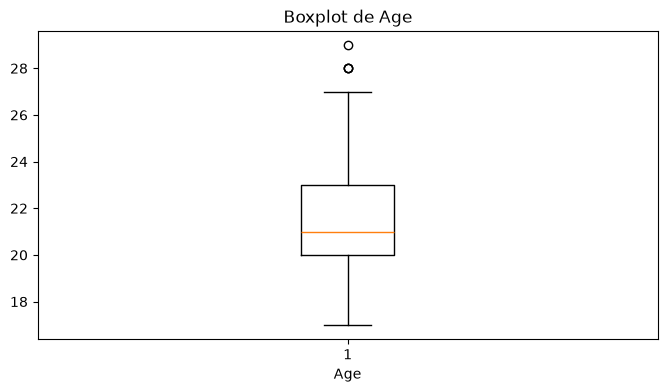

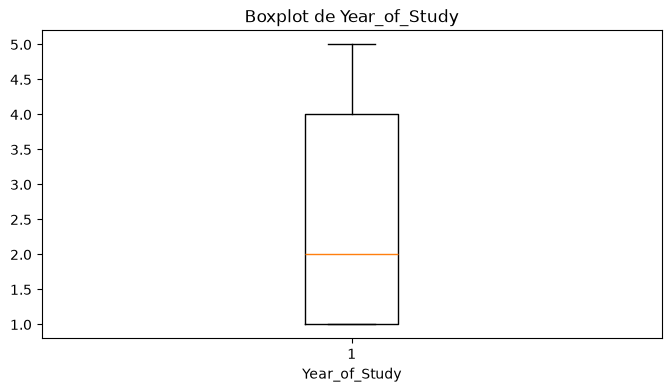

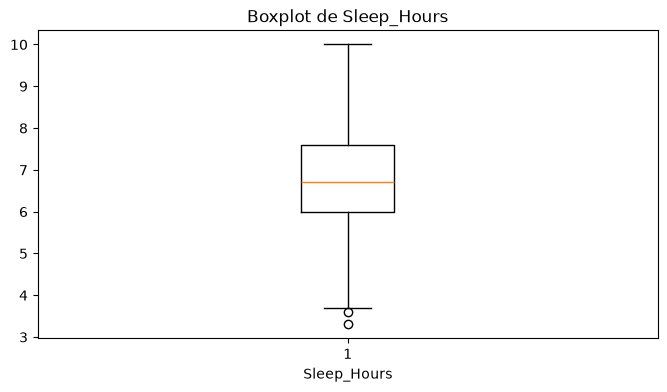

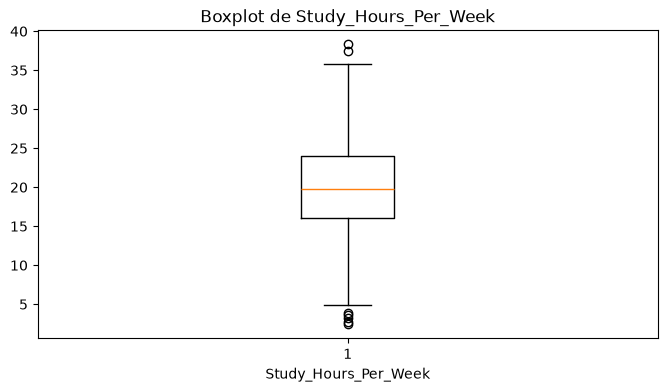

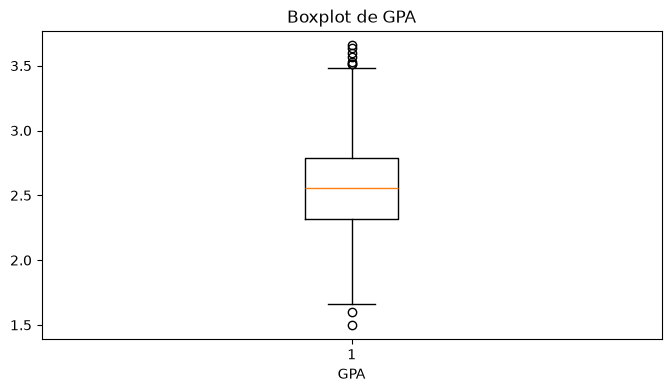

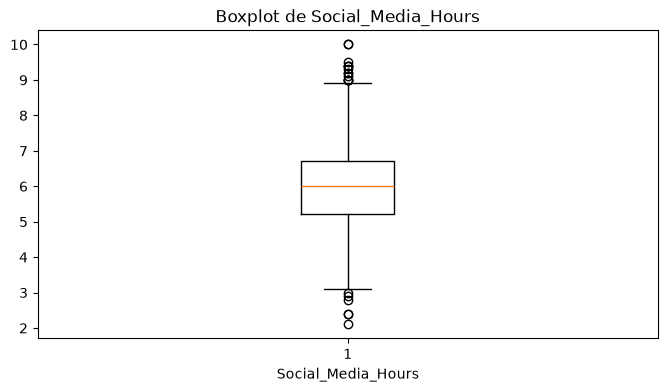

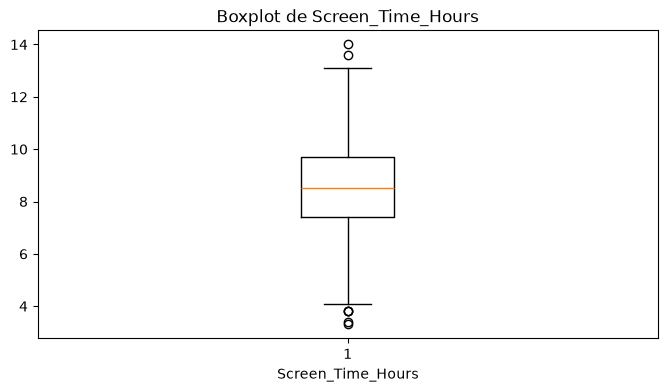

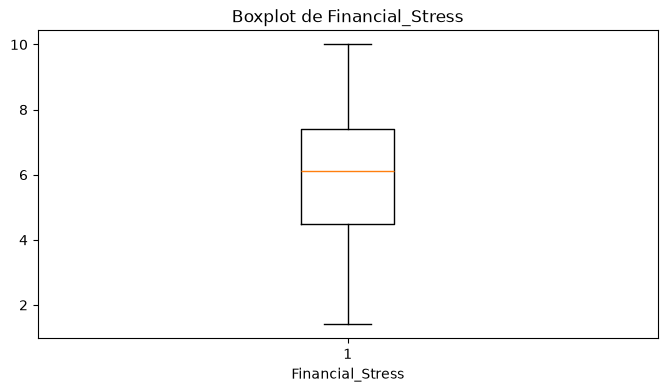

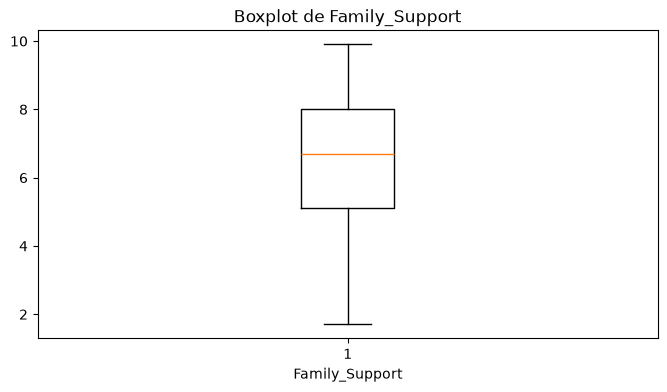

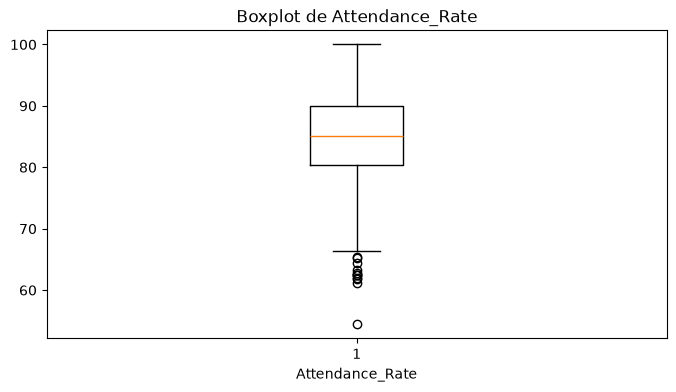

In [9]:
import matplotlib.pyplot as plt

for col in df_numeriques.columns:

    plt.figure(figsize=(8, 4))

    plt.boxplot(df[col].dropna())

    plt.title(f"Boxplot de {col}")
    plt.xlabel(col)

    plt.show()

In [12]:
print("les valeurs inchoerent pour Age : ",((df["Age"]<=0) | (df["Age"]>120)).sum())

les valeurs inchoerent pour Age :  0


In [13]:
print("year_of_study : ", ((~df["Year_of_Study"].between(1,5)) | (df["Year_of_Study"]%1!=0)).sum())

year_of_study :  0


In [27]:
print("Sleep_Hours :", ((~df["Sleep_Hours"].between(0,24)).sum()))

Sleep_Hours : 62


In [32]:
print("sleep_Hours superieur a 24 : "  ,(df["Sleep_Hours"]>24).sum())

sleep_Hours superieur a 24 :  0


In [39]:
print("sleep_Hours inferieur a 3 : "  ,(df["Sleep_Hours"]<=4).sum())

sleep_Hours inferieur a 3 :  13


In [40]:
print("Financial_Stress :", (
    (~df["Financial_Stress"].between(1, 10))
).sum())


Financial_Stress : 91


In [41]:
print("Family_Support :", (
    (~df["Family_Support"].between(1, 10))
).sum())

print("Attendance_Rate :", (
    (~df["Attendance_Rate"].between(0, 100))
).sum())

Family_Support : 54
Attendance_Rate : 47


In [ ]:

condition = (
    df["Social_Media_Hours"] >
    df["Screen_Time_Hours"]
)

print("Nombre d'incohérences :", condition.sum())

Nombre d'incohérences : 37


In [43]:
df.loc[condition,["Student_ID", "Social_Media_Hours", "Screen_Time_Hours"]]

,Student_ID,Social_Media_Hours,Screen_Time_Hours
78,STU0079,5.0,4.9
168,STU0169,5.6,5.3
209,STU0210,7.5,7.3
278,STU0279,6.0,5.1
382,STU0383,5.3,4.1
424,STU0425,5.5,4.4
476,STU0477,5.5,5.3
505,STU0506,5.6,5.5
557,STU0558,4.6,4.4
588,STU0589,5.7,5.3


In [45]:
variable_cible = df["Mental_Health_Risk"].value_counts()
variable_cible

Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64

In [49]:
pourcentage = (df["Mental_Health_Risk"].value_counts(normalize=True))*100
pourcentage

Mental_Health_Risk
High      34.0
Medium    33.0
Low       33.0
Name: proportion, dtype: float64

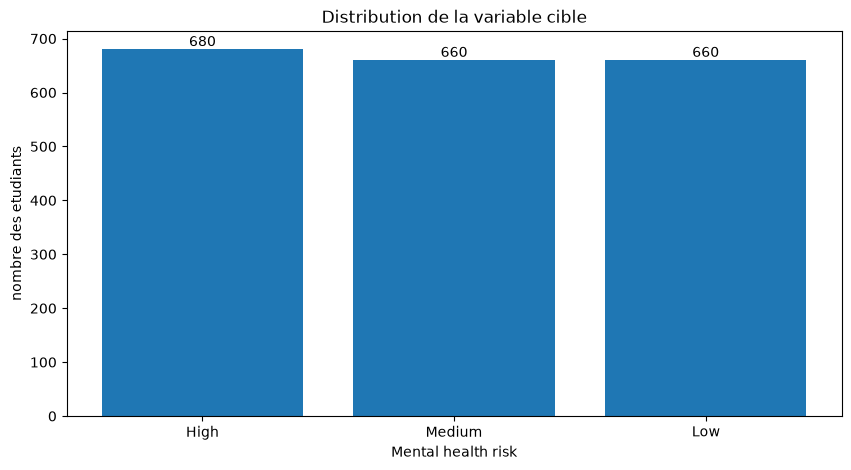

In [60]:
fig,ax = plt.subplots(figsize=(10,5))

distribution = df["Mental_Health_Risk"].value_counts()

barres = ax.bar(distribution.index,distribution.values)
ax.bar_label(barres)

plt.title("Distribution de la variable cible")
plt.xlabel("Mental health risk")
plt.ylabel("nombre des etudiants")

plt.show()

In [68]:
(df["Sleep_Hours"]>22).sum()

np.int64(0)

In [69]:
risk_mapping = {
    "Low" : 0,
    "Medium":1,
    "High":2
}

df["Mental_Health_Risk_Encoded"] = df["Mental_Health_Risk"].map(risk_mapping)

In [75]:
df_numeriques = df.select_dtypes(include=["number"]).columns

correlations = df[df_numeriques].corr()

correlations=correlations["Mental_Health_Risk_Encoded"].drop("Mental_Health_Risk_Encoded").sort_values(ascending=False)

correlations



Financial_Stress        0.313547
Social_Media_Hours      0.207601
Screen_Time_Hours       0.173972
Age                     0.004961
Attendance_Rate        -0.145362
Year_of_Study          -0.166404
Study_Hours_Per_Week   -0.238793
Family_Support         -0.250894
GPA                    -0.352626
Sleep_Hours            -0.541857
Name: Mental_Health_Risk_Encoded, dtype: float64

In [ ]:
corr_matrix= df[df_numeriques].corr()
corr_matrix

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate,Mental_Health_Risk_Encoded
Age,1.000000,0.002186,-0.010572,-0.007476,0.001437,-0.007609,-0.005439,0.004142,-0.010363,-0.009612,0.004961
Year_of_Study,0.002186,1.000000,0.025545,0.703401,0.344012,-0.353989,-0.239093,-0.013438,0.008983,0.078682,-0.166404
Sleep_Hours,-0.010572,0.025545,1.000000,0.032237,0.246255,0.002183,0.019314,0.024435,0.009997,0.076609,-0.541857
Study_Hours_Per_Week,-0.007476,0.703401,0.032237,1.000000,0.492501,-0.501178,-0.333568,-0.025538,0.041464,0.138003,-0.238793
GPA,0.001437,0.344012,0.246255,0.492501,1.000000,-0.225998,-0.158174,0.002308,0.012862,0.285952,-0.352626
Social_Media_Hours,-0.007609,-0.353989,0.002183,-0.501178,-0.225998,1.000000,0.681404,-0.006319,-0.058921,-0.067095,0.207601
Screen_Time_Hours,-0.005439,-0.239093,0.019314,-0.333568,-0.158174,0.681404,1.000000,-0.003091,-0.044414,-0.061941,0.173972
Financial_Stress,0.004142,-0.013438,0.024435,-0.025538,0.002308,-0.006319,-0.003091,1.000000,0.046326,-0.000887,0.313547
Family_Support,-0.010363,0.008983,0.009997,0.041464,0.012862,-0.058921,-0.044414,0.046326,1.000000,0.001640,-0.250894
Attendance_Rate,-0.009612,0.078682,0.076609,0.138003,0.285952,-0.067095,-0.061941,-0.000887,0.001640,1.000000,-0.145362


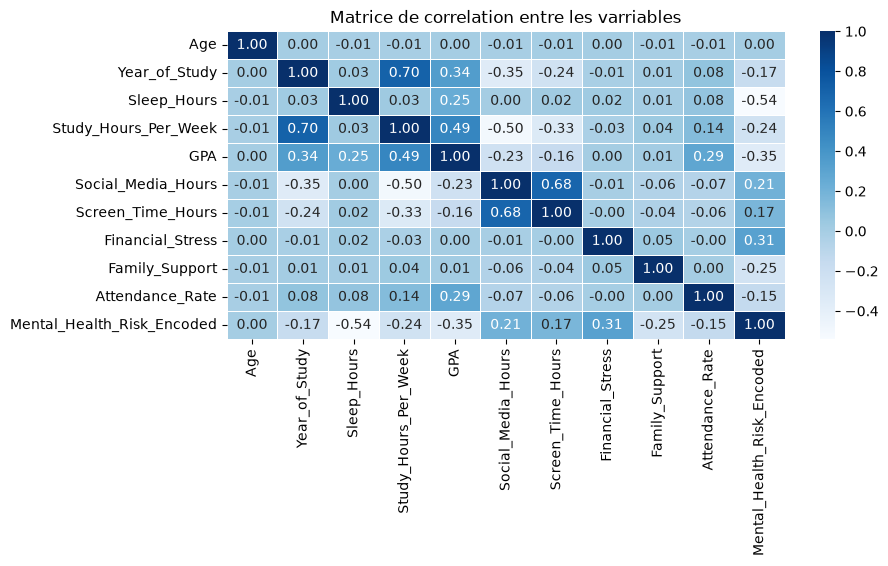

In [89]:
plt.figure(figsize=(9,4))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="Blues",
    fmt=".2f",
    linewidths=0.5
    )

plt.title("Matrice de correlation entre les varriables")
plt.show()

In [90]:
df["Diet_Quality"].value_counts()

Diet_Quality
Average    860
Poor       587
Good       484
Name: count, dtype: int64